In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import joblib

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
df = pd.read_csv("/content/stress_full_dataset.csv")

df


,MEAN_RR,MEDIAN_RR,SDRR,RMSSD,SDSD,SDRR_RMSSD,pNN25,pNN50,KURT,SKEW,...,TP,LF_HF,HF_LF,uuid.2,SD1,SD2,sampen,higuci,datasetId,condition
0,0.309041,853.763730,140.972741,0.140024,15.553371,9.063146,0.157670,-0.335965,-0.856554,0.335218,...,3686.666157,-0.141218,0.015380,89df2855-56eb-4706-a23b-b39363dd605a,11.001565,199.061782,2.139754,1.163485,2,1
1,0.744562,948.357865,81.317742,-0.488516,12.964195,6.272369,-0.517493,-0.874583,-0.408190,-0.155286,...,3006.487251,0.585608,0.003055,80c795e4-aa56-4cc0-939c-19634b89cbb2,9.170129,114.634458,2.174499,1.084711,2,0
2,0.413598,907.006860,84.497236,0.322217,16.305274,5.182201,0.393570,-0.672601,0.351789,-0.656813,...,2685.879461,-0.060125,0.010607,c2d5d102-967c-487d-88f2-8b005a449f3e,11.533417,118.939253,2.135350,1.176315,2,0
3,0.281755,893.460030,90.370537,0.180299,15.720068,5.748591,0.239014,-0.739928,-0.504947,-0.386138,...,3434.520980,-0.168069,0.018074,37eabc44-1349-4040-8896-0d113ad4811f,11.119476,127.318597,2.178341,1.179688,2,1
4,-0.297140,811.184865,62.766242,1.028043,19.213657,3.266724,1.263959,-0.672601,-0.548408,-0.154252,...,2621.175204,-0.239679,0.033912,aa777a6a-7aa3-4f6e-aced-70f8691dd2b7,13.590641,87.718281,2.221121,1.249612,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
369284,-1.005212,721.533965,36.377559,-1.302565,9.609936,3.785409,-1.086906,-0.874583,1.007321,0.075965,...,649.351702,-0.298697,0.122087,028ae89f-0120-4808-955f-f6b3ecaa59b3,6.797519,50.994582,2.096850,1.314910,2,1
369285,1.104432,978.622945,74.918433,-0.294903,13.761705,5.443754,-0.428013,-0.672601,0.248964,0.167716,...,2278.456746,0.450892,0.003588,03f6d164-b28d-49e8-9e27-0288577408ec,9.734243,105.502548,2.131264,1.175975,2,1
369286,1.435346,1024.968400,95.309200,1.959288,23.050395,4.134664,2.508535,1.212564,-0.429686,-0.075321,...,4331.259564,1.214793,0.001804,fd717478-95c3-48fc-bcdc-3adebae824ab,16.304530,133.797793,2.215643,1.140232,2,1
369287,-0.389450,803.559610,78.449897,0.426909,16.736657,4.687302,0.019383,0.606618,0.600389,-0.634762,...,2930.056129,-0.245507,0.036516,a0fc861e-3254-4210-bd5d-37870245f7da,11.838553,110.311474,2.091628,1.181937,2,1


In [ ]:
print("Shape :", df.shape)
df.info()


Shape : (369289, 38)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 369289 entries, 0 to 369288
Data columns (total 38 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   MEAN_RR            369289 non-null  float64
 1   MEDIAN_RR          369289 non-null  float64
 2   SDRR               369289 non-null  float64
 3   RMSSD              369289 non-null  float64
 4   SDSD               369289 non-null  float64
 5   SDRR_RMSSD         369289 non-null  float64
 6   pNN25              369289 non-null  float64
 7   pNN50              369289 non-null  float64
 8   KURT               369289 non-null  float64
 9   SKEW               369289 non-null  float64
 10  MEAN_REL_RR        369289 non-null  float64
 11  MEDIAN_REL_RR      369289 non-null  float64
 12  SDRR_REL_RR        369289 non-null  float64
 13  RMSSD_REL_RR       369289 non-null  float64
 14  SDSD_REL_RR        369289 non-null  float64
 15  SDRR_RMSSD_REL_RR  369289 non-

In [ ]:
df = df.loc[:, ~df.columns.duplicated()]

print("After removing duplicate columns:", df.shape)


After removing duplicate columns: (369289, 38)


In [ ]:
# ---------------------------
# Drop non-ML identifier columns
# ---------------------------

cols_to_drop = [c for c in df.columns if c.startswith("uuid")]
cols_to_drop += ["datasetId"]

df = df.drop(columns=cols_to_drop)

print("After dropping uuid and datasetId:", df.shape)


After dropping uuid and datasetId: (369289, 34)


In [ ]:
df.isna().sum().sort_values(ascending=False)


,0
MEAN_RR,0
MEDIAN_RR,0
SDRR,0
RMSSD,0
SDSD,0
SDRR_RMSSD,0
pNN25,0
pNN50,0
KURT,0
SKEW,0


In [ ]:
print("Missing values before cleaning:")
print(df.isna().sum().sum())

# Fill missing values with column median
df = df.fillna(df.median(numeric_only=True))

print("Missing values after cleaning:")
print(df.isna().sum().sum())


Missing values before cleaning:
0
Missing values after cleaning:
0


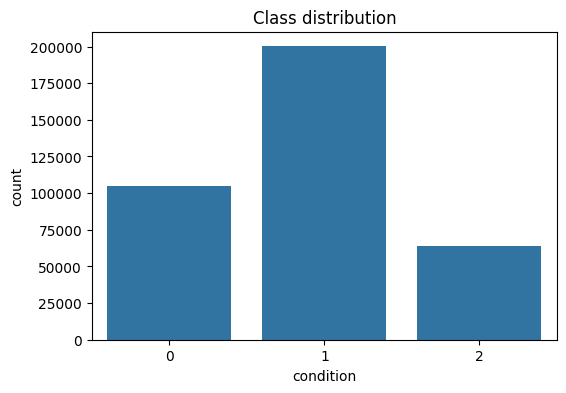

condition
1    200082
0    105150
2     64057
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="condition", data=df)
plt.title("Class distribution")
plt.show()

print(df["condition"].value_counts())


In [ ]:
df.describe()


,MEAN_RR,MEDIAN_RR,SDRR,RMSSD,SDSD,SDRR_RMSSD,pNN25,pNN50,KURT,SKEW,...,HF_PCT,HF_NU,TP,LF_HF,HF_LF,SD1,SD2,sampen,higuci,condition
count,3.692890e+05,369289.000000,369289.000000,3.692890e+05,369289.000000,369289.000000,3.692890e+05,3.692890e+05,369289.000000,369289.000000,...,369289.000000,369289.000000,369289.000000,3.692890e+05,369289.000000,369289.000000,369289.000000,369289.000000,369289.000000,369289.000000
mean,-9.187208e-16,841.965890,109.352531,-4.983375e-18,14.976767,7.396597,6.494743e-17,-1.938514e-16,0.523235,0.041628,...,1.615576,4.433282,3185.356025,3.479704e-17,0.048506,10.593708,154.178997,2.062471,1.182292,0.888724
std,1.000001e+00,132.321005,77.117025,1.000001e+00,4.120768,5.143834,1.000001e+00,1.000001e+00,1.790348,0.699522,...,1.761073,4.123365,1923.227187,1.000001e+00,0.049238,2.914795,109.170222,0.206999,0.062192,0.667694
min,-2.400873e+00,517.293295,27.233947,-2.292721e+00,5.529630,2.660381,-1.200789e+00,-8.745830e-01,-1.894820,-2.136278,...,0.002150,0.012825,377.692795,-3.149668e-01,0.000128,3.911344,38.307745,0.434576,1.033984,0.000000
25%,-6.935708e-01,755.750735,64.205641,-7.635822e-01,11.830671,4.541896,-7.533926e-01,-8.745830e-01,-0.352783,-0.359291,...,0.346803,1.228054,1828.147788,-2.805555e-01,0.012433,8.368340,90.326864,2.032977,1.139929,0.000000
50%,-1.901921e-01,819.689595,82.608243,-1.362808e-01,14.415388,5.952112,-2.734581e-01,-4.032919e-01,0.040736,-0.060966,...,1.039513,3.356860,2796.856587,-2.416138e-01,0.034735,10.196621,116.221063,2.134214,1.174293,1.000000
75%,6.217090e-01,916.821570,118.237002,7.158014e-01,17.924839,7.919841,4.261074e-01,6.066178e-01,0.722833,0.282417,...,2.245115,6.354266,4052.260157,-9.850943e-02,0.067854,12.679005,166.764850,2.181929,1.223621,1.000000
max,3.815026e+00,1653.122250,563.486949,2.827628e+00,26.629392,54.523950,3.606690e+00,4.646257e+00,64.088107,6.777800,...,13.095664,30.120917,13390.684098,2.128410e+01,0.431043,18.836107,796.852945,2.234841,1.361219,2.000000


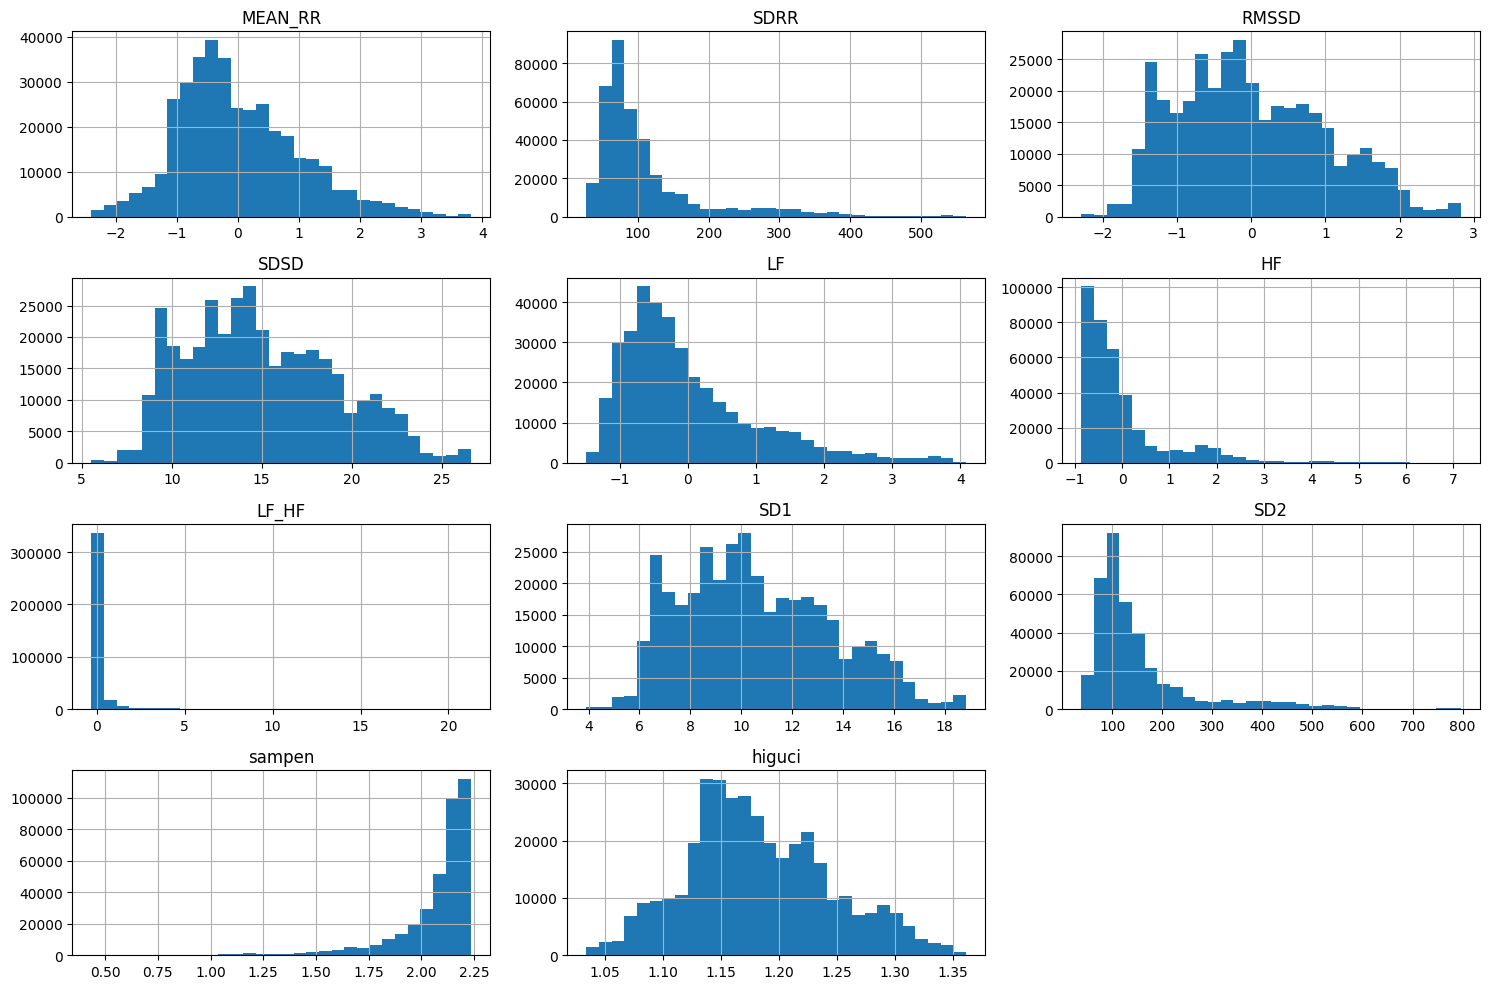

In [ ]:
eda_features = [
    "MEAN_RR",
    "SDRR",
    "RMSSD",
    "SDSD",
    "LF",
    "HF",
    "LF_HF",
    "SD1",
    "SD2",
    "sampen",
    "higuci"
]

df[eda_features].hist(figsize=(15,10), bins=30)
plt.tight_layout()
plt.show()


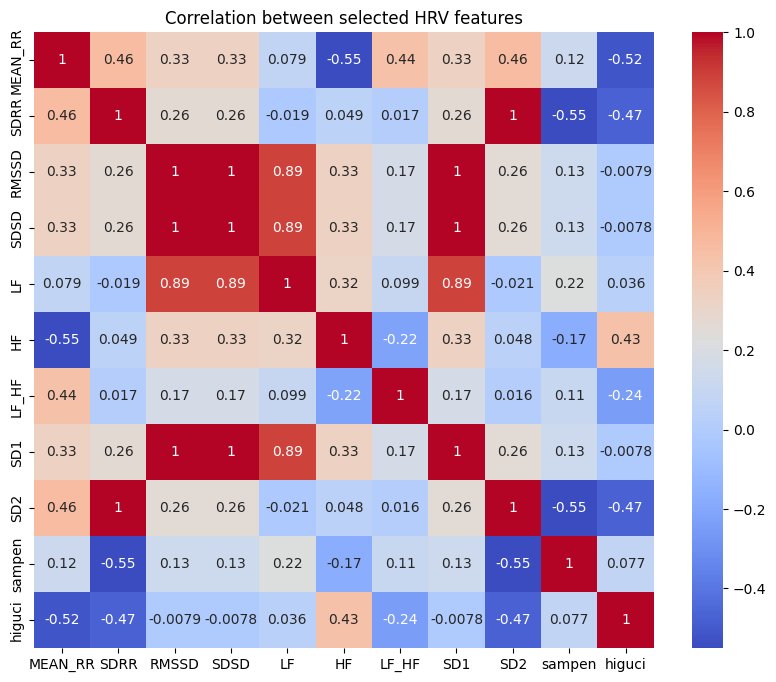

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(
    df[eda_features].corr(),
    cmap="coolwarm",
    annot=True
)
plt.title("Correlation between selected HRV features")
plt.show()


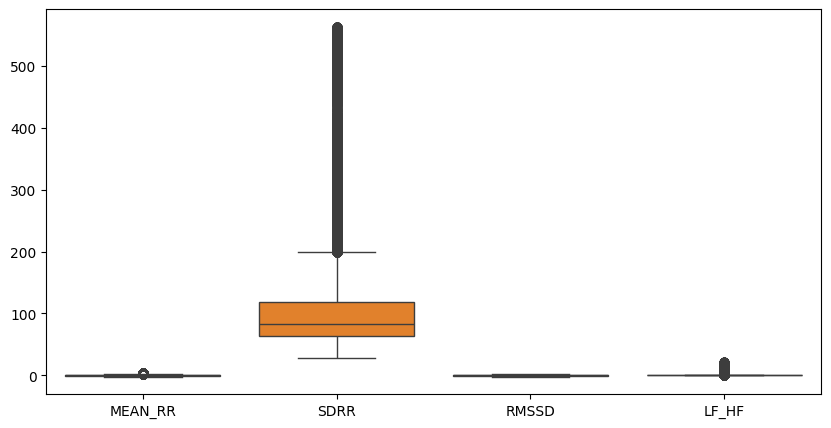

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df[["MEAN_RR","SDRR","RMSSD","LF_HF"]])
plt.show()


In [ ]:
cols_to_drop = [c for c in df.columns if c.startswith("uuid")]

if "datasetId" in df.columns:
    cols_to_drop.append("datasetId")

df_ml = df.drop(columns=cols_to_drop)

print("Dropped columns:", cols_to_drop)
print(df_ml.shape)


Dropped columns: []
(369289, 34)


In [ ]:
X = df_ml.drop(columns=["condition"])
y = df_ml["condition"]

print(X.shape, y.shape)


(369289, 33) (369289,)


In [ ]:
feature_columns = X.columns.tolist()
joblib.dump(feature_columns, "feature_columns.pkl")

len(feature_columns)


33

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

joblib.dump(scaler, "scaler.pkl")


['scaler.pkl']

In [ ]:
num_classes = y.nunique()

y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_cat  = tf.keras.utils.to_categorical(y_test, num_classes)


In [ ]:
model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,803 (50.01 KB)

 Trainable params: 12,803 (50.01 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:


from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, class_weights))

print(class_weights)

history = model.fit(
    X_train,
    y_train_cat,
    validation_split=0.1,
    epochs=20,
    batch_size=256
)


{np.int64(0): np.float64(1.1706728483119353), np.int64(1): np.float64(0.6152313122793865), np.int64(2): np.float64(1.9216524216524216)}
Epoch 1/50
1039/1039 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6699 - loss: 0.7362 - val_accuracy: 0.9290 - val_loss: 0.2465
Epoch 2/50
1039/1039 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8745 - loss: 0.3256 - val_accuracy: 0.9698 - val_loss: 0.1151
Epoch 3/50
1039/1039 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9231 - loss: 0.2117 - val_accuracy: 0.9847 - val_loss: 0.0667
Epoch 4/50
1039/1039 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9437 - loss: 0.1569 - val_accuracy: 0.9912 - val_loss: 0.0448
Epoch 5/50
1039/1039 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9559 - loss: 0.1262 - val_accuracy: 0.9932 - val_loss: 0.0317
Epoch 6/50
1039/1039 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9635 - loss: 0.1063 - val_accuracy: 0.9958 - val_loss: 0.0225
Epoch 7/50
1039/1039 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9671 - loss: 0.0

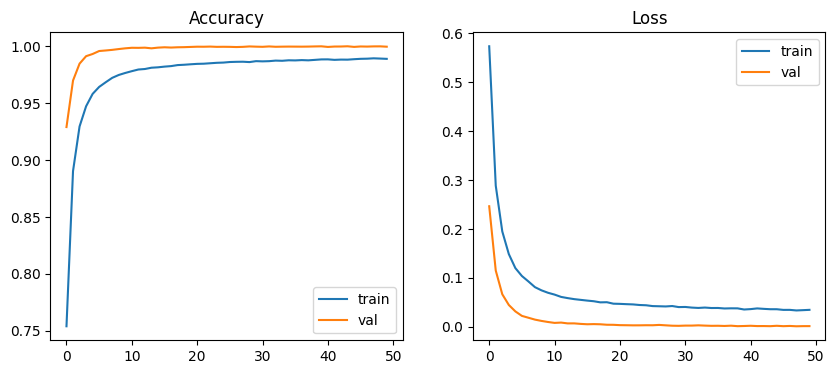

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Accuracy")
plt.legend(["train","val"])

plt.subplot(1,2,2)
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Loss")
plt.legend(["train","val"])

plt.show()


In [ ]:
loss, acc = model.evaluate(X_test, y_test_cat)
print("Test accuracy :", acc)


2309/2309 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9995 - loss: 0.0017
Test accuracy : 0.9996885657310486


In [ ]:
y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Interruption","No stress","Time pressure"]
))


2309/2309 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
               precision    recall  f1-score   support

 Interruption       1.00      1.00      1.00     21030
    No stress       1.00      1.00      1.00     40017
Time pressure       1.00      1.00      1.00     12811

     accuracy                           1.00     73858
    macro avg       1.00      1.00      1.00     73858
 weighted avg       1.00      1.00      1.00     73858



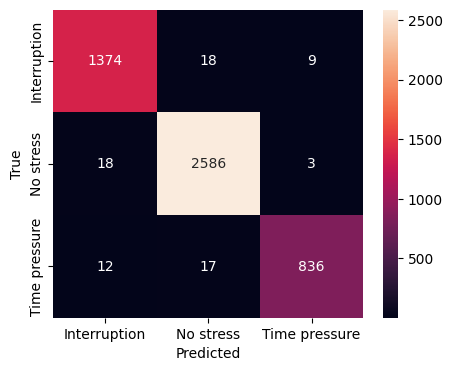

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Interruption","No stress","Time pressure"],
            yticklabels=["Interruption","No stress","Time pressure"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [ ]:
model.save("stress_ann_model.h5")


In [ ]:
row_id = 20

sample = df_ml.iloc[row_id]

x = sample[feature_columns].values.reshape(1,-1)
x = scaler.transform(x)

pred = model.predict(x)
cls = int(np.argmax(pred))

mapping = {0:"Interruption",1:"No stress",2:"Time pressure"}

print("Prediction :", mapping[cls])
print("True label :", mapping[int(sample["condition"])])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Prediction : No stress
True label : No stress


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
import gradio as gr
import numpy as np
import joblib
from tensorflow.keras.models import load_model

model = load_model("stress_ann_model.h5")
scaler = joblib.load("scaler.pkl")
feature_columns = joblib.load("feature_columns.pkl")

def predict_stress(*inputs):

    x = np.array(inputs, dtype=np.float32).reshape(1,-1)
    x = scaler.transform(x)

    pred = model.predict(x)
    cls = int(np.argmax(pred))

    mapping = {
        0: "Interruption",
        1: "No stress",
        2: "Time pressure"
    }

    return mapping[cls]


inputs = [gr.Number(label=col) for col in feature_columns]

demo = gr.Interface(
    fn=predict_stress,
    inputs=inputs,
    outputs=gr.Textbox(label="Prediction"),
    title="HRV based Stress Detection using ANN"
)

demo.launch(debug=True)


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://3b6d823596938df90f.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://3b6d823596938df90f.gradio.live
